<a href="https://colab.research.google.com/github/mahak315/sdav_lab/blob/main/Copy_of_Lab_Pgm_1_Exercise_Qs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab Program 1
## Probability Computation, Conditional Probability & Bayes' Theorem: Simulate and visualize probability experiments, verify addition and multiplication rules, compute conditional probabilities, and apply Bayes' Theorem to real-world classification scenarios. (CO1)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import itertools

In [ ]:
np.random.seed(42)

# --- PART 1A: Classical Probability ---
coin_space = ['H', 'T']
two_coin = list(itertools.product(coin_space, coin_space))
print('Sample Space:', two_coin)

Sample Space: [('H', 'H'), ('H', 'T'), ('T', 'H'), ('T', 'T')]


In [ ]:
two_heads = [s for s in two_coin if s.count('H') == 2]
P_2H = len(two_heads) / len(two_coin)
print(f'P(2 Heads) = {P_2H}')

P(2 Heads) = 0.25


## PART 1A — Dice Addition Rule
### Now the program demonstrates the addition rule of probability.

In [ ]:
# Dice - Addition Rule
dice = list(range(1, 7))
A = [x for x in dice if x % 2 == 0]   # Even
B = [x for x in dice if x > 3]          # Greater than 3
P_A = len(A)/6;  P_B = len(B)/6
P_AB = len(set(A)&set(B))/6
print(f'P(A∪B) = P(A)+P(B)-P(A∩B) = {P_A+P_B-P_AB:.4f}')

P(A∪B) = P(A)+P(B)-P(A∩B) = 0.6667


## PART 1B: Empirical Probability
### Now the program moves from theoretical probability to experimental probability.

In [ ]:
# --- PART 1B: Empirical Convergence ---
for n in [10, 100, 1000, 10000]:
    tosses = np.random.binomial(1, 0.5, n)
    print(f'n={n:>6}: P(H)={tosses.mean():.4f}')

n=    10: P(H)=0.6000
n=   100: P(H)=0.4500
n=  1000: P(H)=0.5050
n= 10000: P(H)=0.4940


## PART 1C: Bayes' Theorem
### This is the most important statistical section of the program.
### The example considers a medical diagnostic test.

In [ ]:
# --- PART 1C: Bayes' Theorem ---
P_Disease = 0.01    # Only 1% of the population has the disease.
P_Pos_D   = 0.99    # Sensitivity - If a person has the disease, the probability that the test is positive is 99%.
P_Pos_ND  = 0.05    # False Positive Rate - If a person does NOT have the disease, there is still a 5% probability that the test is positive.


# Total Probability
P_Pos = P_Pos_D*P_Disease + P_Pos_ND*(1-P_Disease)
# Bayes' Theorem
P_D_Pos = (P_Pos_D * P_Disease) / P_Pos
print(f'P(Disease | Positive) = {P_D_Pos:.4f} ({P_D_Pos*100:.2f}%)')

P(Disease | Positive) = 0.1667 (16.67%)


# PART 2: Visualization
## The final section demonstrates the Law of Large Numbers visually.

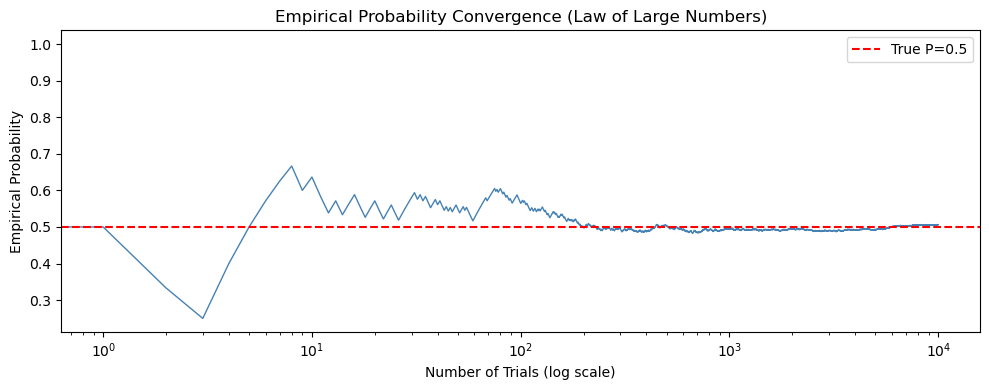

In [ ]:
# --- VISUALIZATION ---
# Empirical convergence plot
n_total = 10000
tosses  = np.random.binomial(1, 0.5, n_total)
emp_prob = [tosses[:i].mean() for i in range(1, n_total+1)]
plt.figure(figsize=(10,4))
plt.plot(emp_prob, color='steelblue', linewidth=1)
plt.axhline(0.5, color='red', linestyle='--', label='True P=0.5')
plt.xscale('log')
plt.title('Empirical Probability Convergence (Law of Large Numbers)')
plt.xlabel('Number of Trials (log scale)')
plt.ylabel('Empirical Probability')
plt.legend(); plt.tight_layout(); plt.show()

## Inference from the Graph
### The graph demonstrates the Law of Large Numbers through repeated simulation of a fair coin toss.
- The red dashed line at 0.5 represents the theoretical probability of obtaining Heads.
- For a small number of trials, the empirical probability fluctuates significantly, ranging approximately from 0.25 to 0.67.
- As the number of trials increases, these fluctuations gradually decrease.
- After a few hundred trials, the empirical probability becomes increasingly close to 0.5.
- At around 1,000–10,000 trials, the curve remains very close to the theoretical probability of 0.5.
- Therefore, the graph confirms that as the number of independent trials increases, the empirical probability converges toward the theoretical probability.

The graph clearly demonstrates the Law of Large Numbers. For a small number of trials, the empirical probability of obtaining Heads varies considerably due to random fluctuations. However, as the number of trials increases, the empirical probability gradually converges toward the theoretical probability of 0.5. Hence, a larger number of trials provides a more reliable estimate of the true probability.

# Exercise Questions

1. Coin Toss Probability
Write a Python program to generate the sample space for three coin tosses and calculate the probability of:
- a) Getting exactly 3 Heads
- b) Getting exactly 2 Heads
- c) Getting at least 1 Head
Hint: Use itertools.product().

2. Dice Probability
Write a Python program to calculate the probability of getting:
- a) An even number
- b) An odd number
- c) A number greater than 4
- d) A number less than or equal to 3
Use the sample space of a single die.

3. Two-Dice Experiment
Generate the sample space for rolling two dice and calculate the probability that:
- a) The sum is 7
- b) The sum is greater than 8
- c) Both dice show the same number
- d) At least one die shows 6
Hint: Use itertools.product(range(1,7), range(1,7)).

![SDAV_Lab_Q4.png](attachment:0496b173-357b-4227-89a3-20699b9568fc.png)

5. Law of Large Numbers
Simulate 10,000 fair coin tosses and calculate the cumulative probability of Heads after every toss.
Plot:
- X-axis → Number of tosses
- Y-axis → Cumulative probability of Heads
- Horizontal line → \(P(H)=0.5\)
Use a logarithmic X-axis.

6. Conditional Probability with Dice
Roll a die.
Define:
- \(A\): number is even
- \(B\): number is greater than 3
- Write a program to calculate: P(A|B)
- Verify the result manually.

7. Bayes' Theorem - Medical Test Problem
A disease affects 2% of a population.
A diagnostic test has:
- Sensitivity = 95%
- False-positive rate = 4%
- Write a Python program to calculate: P(Disease|Positive)
- Display the answer as a percentage.

8. Email Classification
- Suppose: 20% of emails are spam.
- A spam email contains the word "offer" with probability 80%.
- A non-spam email contains offer with probability 10%.
- Using Bayes theorem, calculate: P(Spam|offer)
- Write a Python program to display the result.

In [3]:
#1
coin_space = ['H', 'T']
three_coin = list(itertools.product(coin_space, coin_space,coin_space))
print('Sample Space:', three_coin)
#a)
three_heads = [s for s in three_coin if s.count('H') == 3]
P_3H = len(three_heads) / len(three_coin)
print(f'P(exactly 3 Heads) = {P_3H}')
#b)
two_heads = [s for s in three_coin if s.count('H') == 2]
P_2H = len(two_heads) / len(three_coin)
print(f'P(exactly 2 Heads) = {P_2H}')
#c)
at_least_one_head = [s for s in three_coin if 'H' in s]
P_at_least_one_head = len(at_least_one_head) / len(three_coin)
print(f'P(at least one Head) = {P_at_least_one_head}')

Sample Space: [('H', 'H', 'H'), ('H', 'H', 'T'), ('H', 'T', 'H'), ('H', 'T', 'T'), ('T', 'H', 'H'), ('T', 'H', 'T'), ('T', 'T', 'H'), ('T', 'T', 'T')]
P(exactly 3 Heads) = 0.125
P(exactly 2 Heads) = 0.375
P(at least one Head) = 0.875


In [4]:
#2)
#a)
dice = list(range(1, 7))
A = [x for x in dice if x % 2 == 0]
P_A = len(A)/6
print(f'P(even number) = {P_A}')
#b)
dice = list(range(1, 7))
A = [x for x in dice if x % 2 != 0]
P_A = len(A)/6
print(f'P(odd number) = {P_A}')
#c)
dice = list(range(1, 7))
B = [x for x in dice if x > 4]
P_B = len(B)/6
print(f'P(no. greater than 4) = {P_B}')
#d)
dice = list(range(1, 7))
B = [x for x in dice if x <= 3]
P_B = len(B)/6
print(f'P(no. less than or equal to 3) = {P_B}')

P(even number) = 0.5
P(odd number) = 0.5
P(no. greater than 4) = 0.3333333333333333
P(no. less than or equal to 3) = 0.5


In [5]:
#3)
dice=list(itertools.product(list(range(1,7)),list(range(1,7))))
print('Sample Space:', dice)
#a)
sum_7 = [s for s in dice if sum(s) == 7]
P_sum_7 = len(sum_7) / len(dice)
print(f'P(sum is 7) = {P_sum_7:.2f}')
#b)
sum_8 = [s for s in dice if sum(s) > 8]
P_sum_8 = len(sum_8) / len(dice)
print(f'P(sum is greater than 8) = {P_sum_8:.2f}')
#c)
same = [s for s in dice if s[0]==s[1]]
P_same = len(same) / len(dice)
print(f'P(both dice show the same no.) = {P_same:.2f}')
#d)
at_least_one_6 = [s for s in dice if 6 in s]
P_at_least_one_6 = len(at_least_one_6) / len(dice)
print(f'P(at least one 6) = {P_at_least_one_6:.2f}')

Sample Space: [(1, 1), (1, 2), (1, 3), (1, 4), (1, 5), (1, 6), (2, 1), (2, 2), (2, 3), (2, 4), (2, 5), (2, 6), (3, 1), (3, 2), (3, 3), (3, 4), (3, 5), (3, 6), (4, 1), (4, 2), (4, 3), (4, 4), (4, 5), (4, 6), (5, 1), (5, 2), (5, 3), (5, 4), (5, 5), (5, 6), (6, 1), (6, 2), (6, 3), (6, 4), (6, 5), (6, 6)]
P(sum is 7) = 0.17
P(sum is greater than 8) = 0.28
P(both dice show the same no.) = 0.17
P(at least one 6) = 0.31


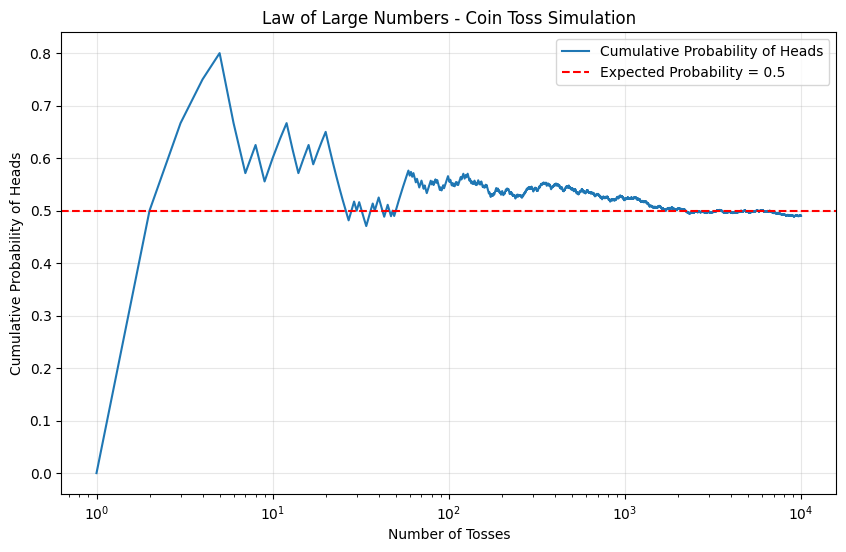

In [6]:
#5)

import numpy as np
import matplotlib.pyplot as plt

# Number of coin tosses
n = 10000

# Simulate 10,000 fair coin tosses
# 1 = Heads, 0 = Tails
tosses = np.random.randint(0, 2, n)

# Cumulative number of Heads
cumulative_heads = np.cumsum(tosses)

# Number of tosses: 1 to 10,000
number_of_tosses = np.arange(1, n + 1)

# Cumulative probability of Heads
cumulative_probability = cumulative_heads / number_of_tosses

# Plot the graph
plt.figure(figsize=(10, 6))

plt.plot(number_of_tosses, cumulative_probability,
         label="Cumulative Probability of Heads")

# Horizontal line at P(H) = 0.5
plt.axhline(y=0.5, color='red', linestyle='--',
            label="Expected Probability = 0.5")

# Logarithmic X-axis
plt.xscale('log')

plt.xlabel("Number of Tosses")
plt.ylabel("Cumulative Probability of Heads")
plt.title("Law of Large Numbers - Coin Toss Simulation")

plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [7]:
#6)
# Conditional Probability with Dice

A = {2, 4, 6}  # Even numbers
B = {4, 5, 6}  # Numbers greater than 3

# Outcomes common to A and B
intersection = A.intersection(B)

# Conditional probability P(A|B)
probability = len(intersection) / len(B)

print("P(A|B) =", probability)
print("Percentage =", probability * 100, "%")


P(A|B) = 0.6666666666666666
Percentage = 66.66666666666666 %


In [8]:
#7)

# Bayes' Theorem - Medical Test

P_Disease = 0.02
P_NoDisease = 1 - P_Disease

P_Positive_Given_Disease = 0.95
P_Positive_Given_NoDisease = 0.04

# Total probability of a positive test
P_Positive = (
    P_Positive_Given_Disease * P_Disease
    + P_Positive_Given_NoDisease * P_NoDisease
)

# Bayes' theorem
P_Disease_Given_Positive = (
    P_Positive_Given_Disease * P_Disease
) / P_Positive

print("P(Disease | Positive) =",
      round(P_Disease_Given_Positive * 100, 2), "%")


P(Disease | Positive) = 32.65 %


In [9]:
#8)

# Email Classification using Bayes' Theorem

P_Spam = 0.20
P_NotSpam = 1 - P_Spam

P_Offer_Given_Spam = 0.80
P_Offer_Given_NotSpam = 0.10

# Total probability of finding "offer"
P_Offer = (
    P_Offer_Given_Spam * P_Spam
    + P_Offer_Given_NotSpam * P_NotSpam
)

# Bayes' theorem
P_Spam_Given_Offer = (
    P_Offer_Given_Spam * P_Spam
) / P_Offer

print("P(Spam | offer) =",
      round(P_Spam_Given_Offer * 100, 2), "%")


P(Spam | offer) = 66.67 %
